# F1nalyze — Klasyfikacja 4-klasowa wyników wyścigów F1
*(Wersja 3: odzysk wierszy bez utraty predykcji + cechy ryzyka DNF)*

**Target A:** `positionOrder` (miejsce na mecie) → 4 klasy: wygrana (1) / podium (2–3) / punkty (4–10) / reszta (>10)
**Dane:** F1nalyze Datathon | Train 1950–2013 / Val 2013–2018 / Test 2018–2023

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (f1_score, balanced_accuracy_score,
                              classification_report, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight
try:
    from scipy.optimize import minimize as scipy_minimize
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False
try:
    from lightgbm import LGBMClassifier
    BOOST_TYPE = 'LGB'
except ImportError:
    from xgboost import XGBClassifier
    BOOST_TYPE = 'XGB'

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path('data')
NA_VALS = [r'\N']
KLASY = ['wygrana', 'podium', 'punkty', 'reszta']
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid', palette='tab10')
print(f'Gradient boosting: {BOOST_TYPE}')
print('Biblioteki załadowane.')

Gradient boosting: LGB
Biblioteki załadowane.


## 1. Wczytanie danych i NAPRAWA (Krok 0)

Surowe pliki to **zepsuty iloczyn kartezjański** (train: ~2,8 mln wierszy, **22 089** realnych wpisów `resultId`).
Do każdego wyniku (kierowca × wyścig) doklejono **wiele migawek klasyfikacji generalnej** z różnych rund.

**Czym jest `racerId`?** To **identyfikator wyścigu** danego wyniku (a `raceId_y` to wyścig, z którego pochodzi
doklejona migawka standings). `racerId` **nie ma żadnych braków** i **nie jest** identyfikatorem kierowcy — kto jest
kim mówi `driverId`, a wiersz do zgłoszenia identyfikuje `result_driver_standing`.

**Naprawa = filtr po WIERSZACH, nie kasowanie kolumny.** Zostawiamy wiersz, gdzie `raceId_y == racerId` (migawka dla
*tego* wyścigu) → dokładnie 1 wiersz na `resultId`. Żadna kolumna (`racerId`, `driverId`, `result_driver_standing`)
nie znika, więc **zawsze wiemy, dla kogo przewidujemy**.

**Odzysk zamiast utraty.** Dla ~2% wyników (głównie lata **90./2000.**, *nie* najstarsze ery) nie istnieje migawka
dokładnie dla tego wyścigu. Zamiast je usuwać, podstawiamy **najbliższą wcześniejszą** migawkę, a kolumny stanu
*po* wyścigu (`points_y`, `wins`, `position`, `positionText_y`) zerujemy i imputujemy. Dzięki temu
**nie tracimy ani jednej predykcji** i unikamy wycieku (migawka jest sprzed wyścigu).

In [2]:
# Kolumny stanu PO wyscigu — dla wierszy odzyskanych pochodza z innego wyscigu, wiec je kasujemy
POST_RACE_STANDINGS = ['points_y', 'wins', 'position', 'positionText_y']

exact_parts, fb_parts = [], []
wszystkie_id = set()
for chunk in pd.read_csv(
    DATA_DIR / 'train.csv', dtype=str,
    na_values=NA_VALS, keep_default_na=False, chunksize=200_000
):
    chunk = chunk.assign(
        _ry=pd.to_numeric(chunk['raceId_y'], errors='coerce'),
        _rc=pd.to_numeric(chunk['racerId'],  errors='coerce'),
    )
    wszystkie_id.update(chunk['resultId'].unique())
    # 1) dokladna migawka dla tego wyscigu
    exact_parts.append(chunk[chunk['_ry'] == chunk['_rc']])
    # 2) kandydaci awaryjni: migawka z NAJBLIZSZEGO WCZESNIEJSZEGO wyscigu (max raceId_y < racerId)
    cand = chunk[chunk['_ry'] < chunk['_rc']]
    if len(cand):
        fb_parts.append(cand.loc[cand.groupby('resultId')['_ry'].idxmax()])

train_exact = pd.concat(exact_parts, ignore_index=True)
train_exact['_odzyskany'] = 0
brakujace = wszystkie_id - set(train_exact['resultId'])

fb_all = pd.concat(fb_parts, ignore_index=True) if fb_parts else train_exact.iloc[:0].copy()
fb_all = fb_all[fb_all['resultId'].isin(brakujace)]
fb_all = fb_all.sort_values('_ry').groupby('resultId', as_index=False).tail(1).copy()
fb_all['_odzyskany'] = 1
fb_all.loc[:, POST_RACE_STANDINGS] = np.nan  # stan po wyscigu z innej rundy -> imputacja

train_raw = pd.concat([train_exact, fb_all], ignore_index=True).drop(columns=['_ry', '_rc'])
n_uniq = train_raw['resultId'].nunique()
nieodzyskane = len(brakujace) - len(fb_all)

assert len(train_raw) == n_uniq, 'BLAD: nie 1 wiersz na resultId!'
print(f'train: {len(train_raw):,} wierszy | {n_uniq:,} unikalnych resultId (z {len(wszystkie_id):,} w pliku)')
print(f'  dokladna migawka: {(train_raw["_odzyskany"]==0).sum():,}'
      f' | odzyskane: {(train_raw["_odzyskany"]==1).sum():,}'
      f' | nieodzyskane: {nieodzyskane}')
print('Weryfikacja OK (1 wiersz = 1 resultId, brak utraconych predykcji)')

train: 21,966 wierszy | 21,966 unikalnych resultId (z 22,089 w pliku)
  dokladna migawka: 21,643 | odzyskane: 323 | nieodzyskane: 123
Weryfikacja OK (1 wiersz = 1 resultId, brak utraconych predykcji)


In [3]:
def wczytaj_i_napraw(sciezka):
    df = pd.read_csv(sciezka, dtype=str, na_values=NA_VALS, keep_default_na=False)
    df = df.assign(
        _ry=pd.to_numeric(df['raceId_y'], errors='coerce'),
        _rc=pd.to_numeric(df['racerId'],  errors='coerce'),
    )
    exact = df[df['_ry'] == df['_rc']].copy()
    exact['_odzyskany'] = 0
    brak = set(df['resultId'].unique()) - set(exact['resultId'])
    cz = df[df['resultId'].isin(brak) & (df['_ry'] < df['_rc'])].copy()
    if len(cz):
        cz = cz.sort_values('_ry').groupby('resultId', as_index=False).tail(1).copy()
        cz['_odzyskany'] = 1
        cz.loc[:, POST_RACE_STANDINGS] = np.nan
    out = pd.concat([exact, cz], ignore_index=True).drop(columns=['_ry', '_rc'])
    n = out['resultId'].nunique()
    assert len(out) == n, f'BLAD: {sciezka}'
    return out, len(df['resultId'].unique()) - n

val_raw,  miss_val  = wczytaj_i_napraw(DATA_DIR / 'validation.csv')
test_raw, miss_test = wczytaj_i_napraw(DATA_DIR / 'test.csv')
print(f'val:  {len(val_raw):,} (odzyskane {int((val_raw["_odzyskany"]==1).sum())}, nieodzyskane {miss_val})')
print(f'test: {len(test_raw):,} (odzyskane {int((test_raw["_odzyskany"]==1).sum())}, nieodzyskane {miss_test})')

val:  1,836 (odzyskane 1, nieodzyskane 0)
test: 2,133 (odzyskane 3, nieodzyskane 0)


In [4]:
COLS_NUM = [
    'resultId','racerId','driverId','constructorId','grid',
    'positionOrder','points','laps','timetaken_in_millisec',
    'fastestLap','rank','statusId','year','round','circuitId',
    'driverStandingsId','raceId_y','points_y','wins'
]
def konwertuj_typy(df):
    df = df.copy()
    for col in COLS_NUM:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    if 'position' in df.columns:
        df['position'] = pd.to_numeric(df['position'], errors='coerce')
    df['dob']  = pd.to_datetime(df.get('dob'),  errors='coerce')
    df['date'] = pd.to_datetime(df.get('date'), errors='coerce')
    return df

train = konwertuj_typy(train_raw)
val   = konwertuj_typy(val_raw)
test  = konwertuj_typy(test_raw)
print(f'train: {train.shape} | val: {val.shape} | test: {test.shape}')

train: (21966, 56) | val: (1836, 56) | test: (2133, 56)


## 2. EDA — eksploracja danych (po naprawie)

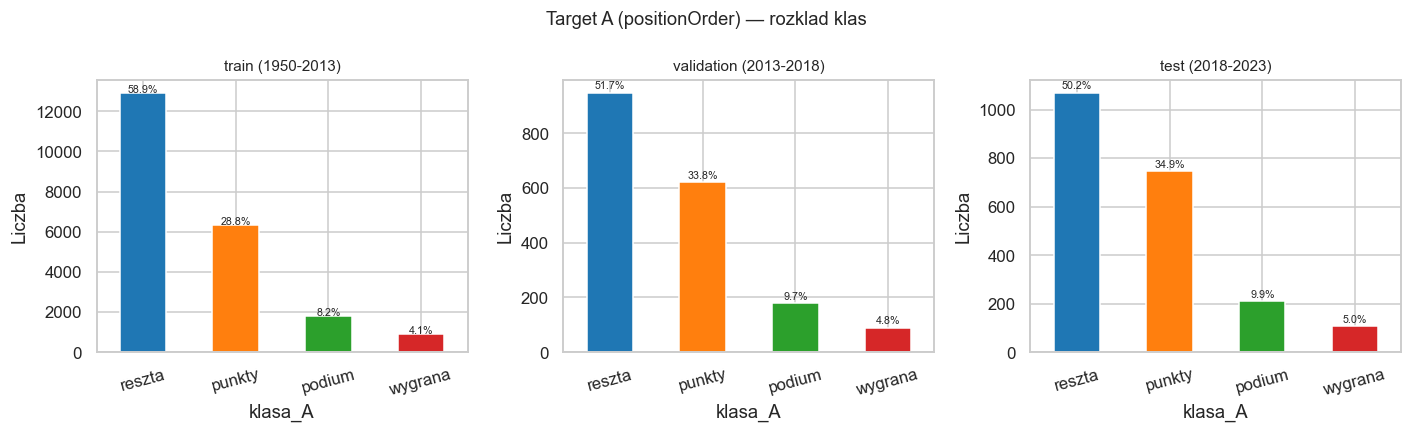

Train: {'reszta': 12933, 'punkty': 6321, 'podium': 1812, 'wygrana': 900}


In [5]:
def mapuj_klasy(s):
    s = pd.to_numeric(s, errors='coerce')
    return pd.cut(s, bins=[0, 1, 3, 10, np.inf],
                  labels=['wygrana', 'podium', 'punkty', 'reszta'], right=True)

train['klasa_A'] = mapuj_klasy(train['positionOrder'])
val['klasa_A']   = mapuj_klasy(val['positionOrder'])
test['klasa_A']  = mapuj_klasy(test['positionOrder'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, df, name in [(axes[0], train, 'train (1950-2013)'),
                     (axes[1], val,   'validation (2013-2018)'),
                     (axes[2], test,  'test (2018-2023)')]:
    cnt = df['klasa_A'].value_counts()
    cnt.plot(kind='bar', ax=ax, color=sns.color_palette('tab10', 4))
    ax.set_title(name, fontsize=10)
    ax.tick_params(axis='x', rotation=15)
    ax.set_ylabel('Liczba')
    for p in ax.patches:
        pct = p.get_height() / len(df) * 100
        if pct > 0:
            ax.annotate(f'{pct:.1f}%',
                        (p.get_x() + p.get_width()/2, p.get_height() + 15),
                        ha='center', fontsize=7)
plt.suptitle('Target A (positionOrder) — rozklad klas', fontsize=12)
plt.tight_layout()
plt.show()
print('Train:', {k: int(v) for k, v in train['klasa_A'].value_counts().items()})

**Uwaga o spójności klas i usunięciu Target B:**
- Klasy wygrana / podium / punkty to pojęcia **wyścigowe** — pasują do `positionOrder` (Target A).
- W train (1950–2013) klasa „punkty (4–10)" oznacza **pasmo pozycji końcowych**, nie dosłowne punkty (przed 2003 punktował top 5/6/8). Zbiory val i test (2013–2023) są w erze top-10 — ocena jest spójna.
- **Target B (`position`) usunięty.** Pojęcia podium/punkty nie mają sensu dla klasyfikacji generalnej. Dominowała reguła trywialna (macro-F1 ≈ 0.86) z powodu autokorelacji tabeli.

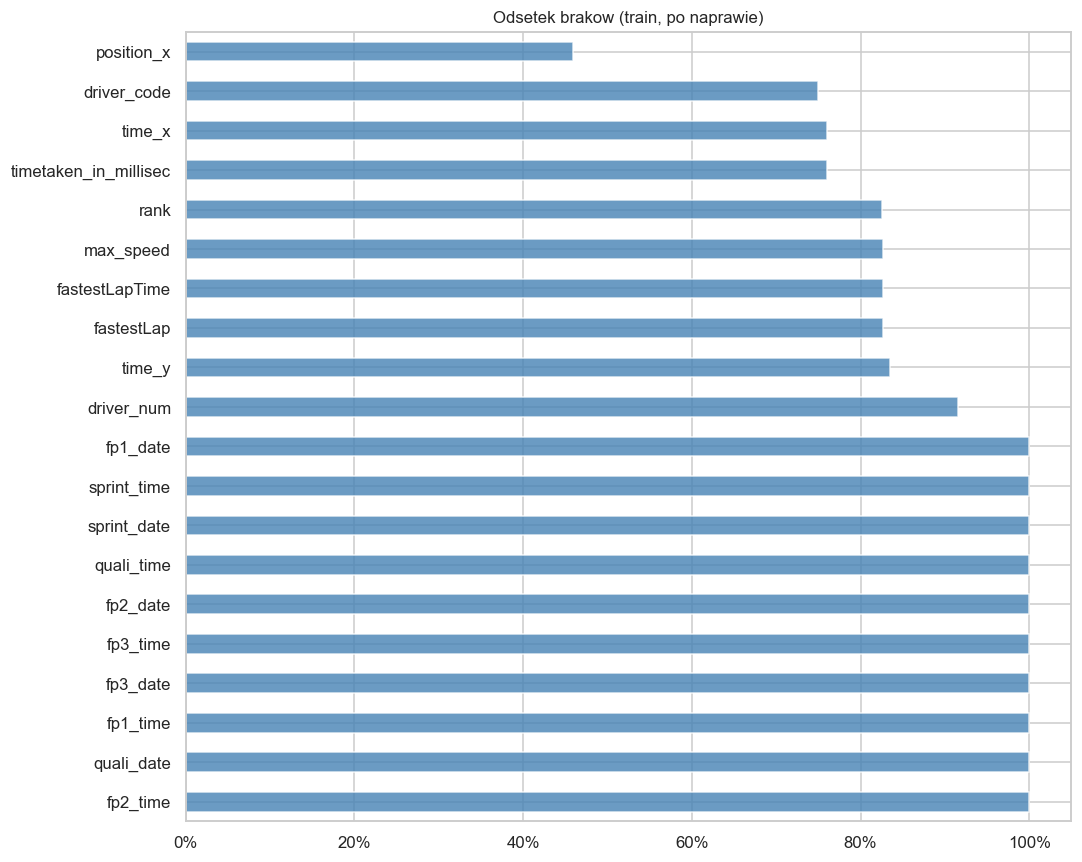

fp2_time                 1.000000
quali_date               1.000000
fp1_time                 1.000000
fp3_date                 1.000000
fp3_time                 1.000000
fp2_date                 1.000000
quali_time               1.000000
sprint_date              1.000000
sprint_time              1.000000
fp1_date                 1.000000
driver_num               0.915415
time_y                   0.835018
fastestLap               0.826869
fastestLapTime           0.826869
max_speed                0.826869
rank                     0.825002
timetaken_in_millisec    0.760311
time_x                   0.760266
driver_code              0.749112
position_x               0.458982


In [6]:
braki = train.isnull().mean().sort_values(ascending=False)
braki_nz = braki[braki > 0].head(20)
fig, ax = plt.subplots(figsize=(10, max(3, len(braki_nz) * 0.4)))
braki_nz.plot(kind='barh', ax=ax, color='steelblue', alpha=0.8)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title('Odsetek brakow (train, po naprawie)', fontsize=11)
plt.tight_layout()
plt.show()
print(braki_nz.to_string())

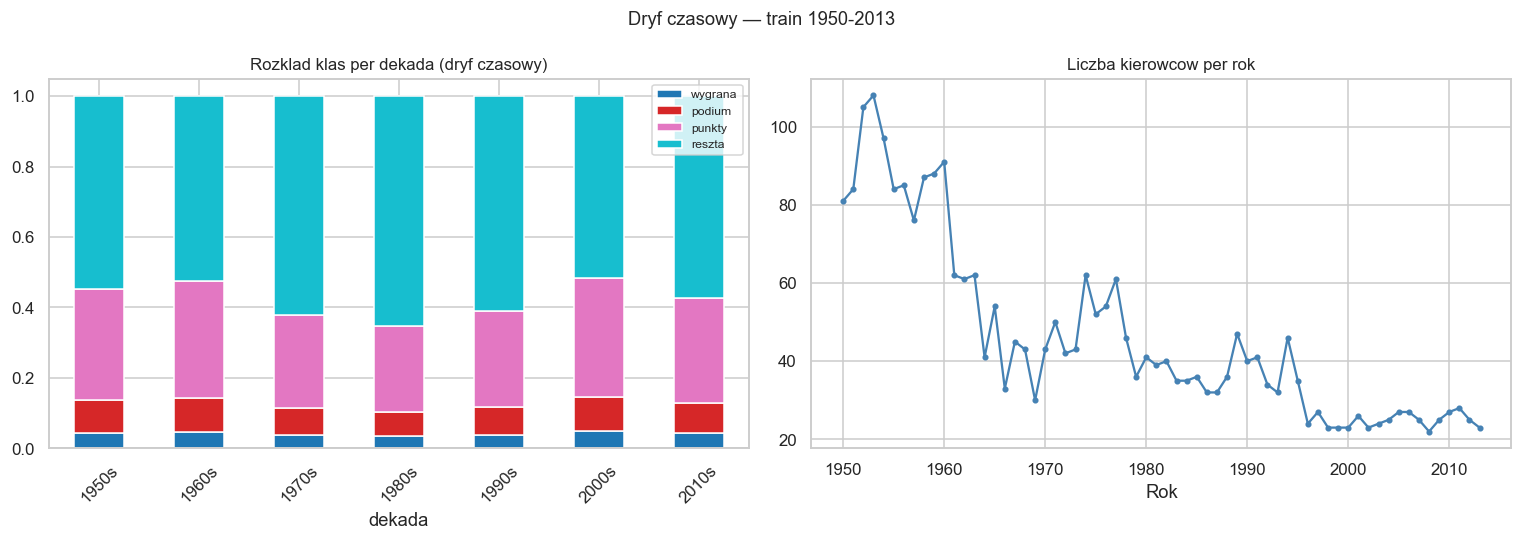

In [7]:
df_drift = train.copy()
df_drift['dekada'] = (df_drift['year'] // 10 * 10).astype(int).astype(str) + 's'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cross = df_drift.groupby(['dekada', 'klasa_A']).size().unstack(fill_value=0)
cross_pct = cross.div(cross.sum(axis=1), axis=0)
cross_pct[['wygrana', 'podium', 'punkty', 'reszta']].plot(
    kind='bar', stacked=True, ax=axes[0], colormap='tab10')
axes[0].set_title('Rozklad klas per dekada (dryf czasowy)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(loc='upper right', fontsize=8)

drv = train.groupby('year')['driverId'].nunique()
axes[1].plot(drv.index, drv.values, 'o-', markersize=3, color='steelblue')
axes[1].set_title('Liczba kierowcow per rok', fontsize=11)
axes[1].set_xlabel('Rok')
plt.suptitle('Dryf czasowy — train 1950-2013', fontsize=12)
plt.tight_layout()
plt.show()

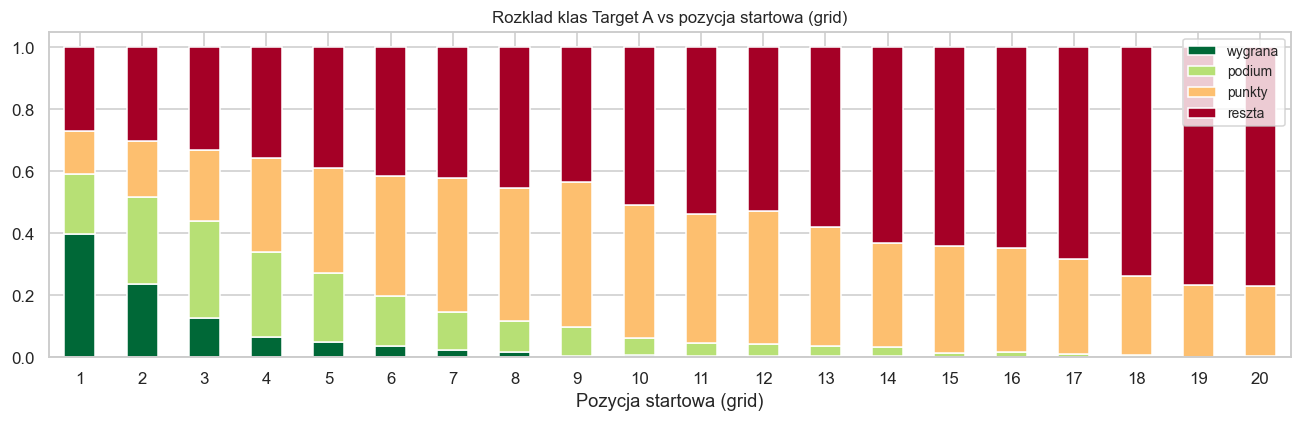

Wniosek: grid to najsilniejszy predyktor.


In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
gk = (train[train['grid'].between(1, 20)]
      .groupby('grid')['klasa_A']
      .value_counts(normalize=True)
      .unstack(fill_value=0))
gk[['wygrana', 'podium', 'punkty', 'reszta']].plot(
    kind='bar', stacked=True, ax=ax, colormap='RdYlGn_r')
ax.set_title('Rozklad klas Target A vs pozycja startowa (grid)', fontsize=11)
ax.set_xlabel('Pozycja startowa (grid)')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
print('Wniosek: grid to najsilniejszy predyktor.')

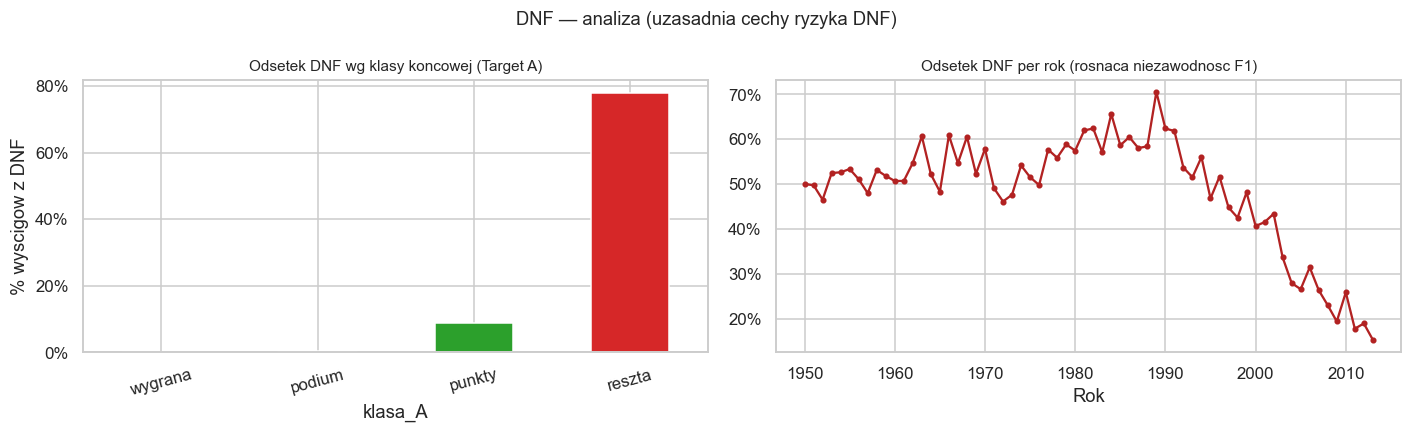

Sredni odsetek DNF (train): 48.5%
Wniosek: DNF mocno przeciaza klase "reszta" -> historyczne ryzyko DNF jest cenna cecha.


In [9]:
# DNF (Did Not Finish): kierowca NIE dojechal do sklasyfikowanej mety.
# Sklasyfikowani = 'Finished' (statusId==1) lub '+N okrazen'; reszta = DNF/awaria/kolizja/DNS/DNQ.
skl_tr = (train['statusId'] == 1) | train['status'].astype(str).str.startswith('+')
train_dnf = (~skl_tr).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tmp = pd.DataFrame({'klasa_A': train['klasa_A'], 'dnf': train_dnf, 'year': train['year']})
dnf_by_cls = tmp.groupby('klasa_A')['dnf'].mean().reindex(KLASY)
dnf_by_cls.plot(kind='bar', ax=axes[0], color=sns.color_palette('tab10', 4))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_title('Odsetek DNF wg klasy koncowej (Target A)', fontsize=10)
axes[0].set_ylabel('% wyscigow z DNF')
axes[0].tick_params(axis='x', rotation=15)

dnf_year = tmp.groupby('year')['dnf'].mean()
axes[1].plot(dnf_year.index, dnf_year.values, 'o-', ms=3, color='firebrick')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_title('Odsetek DNF per rok (rosnaca niezawodnosc F1)', fontsize=10)
axes[1].set_xlabel('Rok')
plt.suptitle('DNF — analiza (uzasadnia cechy ryzyka DNF)', fontsize=12)
plt.tight_layout()
plt.show()
print(f'Sredni odsetek DNF (train): {train_dnf.mean():.1%}')
print('Wniosek: DNF mocno przeciaza klase "reszta" -> historyczne ryzyko DNF jest cenna cecha.')

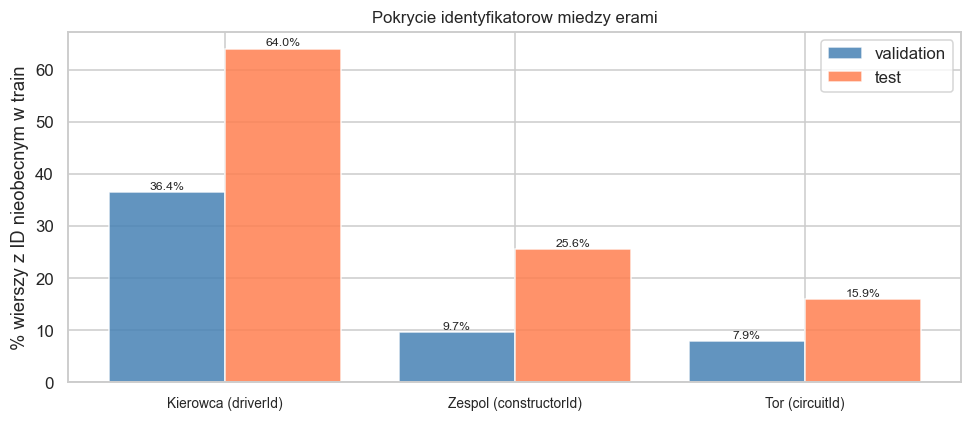

-> driverId: ~64% w test nieznane — usuwamy z cech (szum)
-> constructorId, circuitId: frequency encoding (graceful degradation)


In [10]:
known_drivers      = set(train['driverId'].dropna())
known_constructors = set(train['constructorId'].dropna())
known_circuits     = set(train['circuitId'].dropna())

labels   = ['Kierowca (driverId)', 'Zespol (constructorId)', 'Tor (circuitId)']
val_pct  = [
    (~val['driverId'].isin(known_drivers)).mean() * 100,
    (~val['constructorId'].isin(known_constructors)).mean() * 100,
    (~val['circuitId'].isin(known_circuits)).mean() * 100,
]
test_pct = [
    (~test['driverId'].isin(known_drivers)).mean() * 100,
    (~test['constructorId'].isin(known_constructors)).mean() * 100,
    (~test['circuitId'].isin(known_circuits)).mean() * 100,
]

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, val_pct,  0.4, label='validation', color='steelblue', alpha=0.85)
ax.bar(x + 0.2, test_pct, 0.4, label='test',       color='coral',     alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('% wierszy z ID nieobecnym w train')
ax.set_title('Pokrycie identyfikatorow miedzy erami', fontsize=11)
ax.legend()
for i, (v, t) in enumerate(zip(val_pct, test_pct)):
    ax.text(i - 0.2, v + 0.5, f'{v:.1f}%', ha='center', fontsize=8)
    ax.text(i + 0.2, t + 0.5, f'{t:.1f}%', ha='center', fontsize=8)
plt.tight_layout()
plt.show()
print('-> driverId: ~64% w test nieznane — usuwamy z cech (szum)')
print('-> constructorId, circuitId: frequency encoding (graceful degradation)')

**Wnioski z analizy pokrycia:**
- **`driverId`: 64% nieznanych w test** → surowy `driverId` jako cecha = szum. Usuwamy. Jakość kierowcy nieśiona przez cechy historyczne.
- **`constructorId` (25,6%), `circuitId` (15,9%):** frequency encoding — nieznane ID dostają 0 (neutralne).
- **`nationality`:** niska kardynalność (~50 wartości) → OrdinalEncoder.

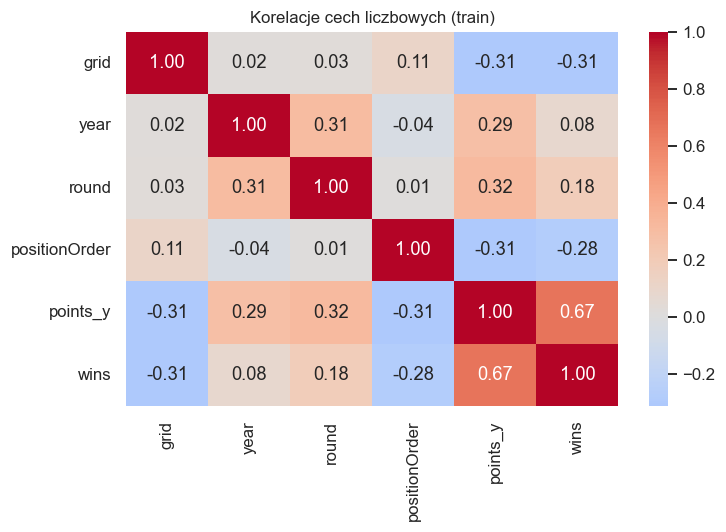

In [11]:
num_cols = ['grid', 'year', 'round', 'positionOrder', 'points_y', 'wins']
num_cols = [c for c in num_cols if c in train.columns]
corr = train[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Korelacje cech liczbowych (train)', fontsize=11)
plt.tight_layout()
plt.show()

## 3. Inżynieria cech — BEZ wycieku danych

### Finalna lista cech

| Cecha | Uzasadnienie |
|---|---|
| `grid` | Pozycja startowa — znana przed wyścigiem |
| `year`, `round` | Czas |
| `wiek_kierowcy` | `(date - dob)` |
| `punkty_przed` | Lag(`points_y`) **całokarierowo** — stan przed wyścigiem |
| `wygrane_przed` | Lag(`wins`) całokarierowo |
| `forma_kierowcy` | Rolling(5, shift=1) `positionOrder` per kierowca |
| `doswiadczenie_kariery` | Cumcount per `driverId` (kariera, nie sezon) |
| `forma_zespolu` | Rolling(5, shift=1) średniej `positionOrder` per zespół per wyścig |
| `dnf_rate_kariera` | Odsetek niedokończonych wyścigów w karierze (lag) — ryzyko awarii/kolizji |
| `dnf_forma_5` | Odsetek DNF w ostatnich 5 wyścigach (lag) — bieżąca niezawodność |
| `chaos_circuit_hist` | Historyczny std(positionOrder−grid) per tor (lag) — proxy mokrego/tech. toru |
| `is_wet_prone` | Binary flag: mokre tory (Spa, Silverstone, Suzuka, Monaco, Interlagos) |
| `driver_circuit_form` | Średnia positionOrder kierowcy NA TYM torze (lag) — znajomość trasy |
| `freq_constructor` | Częstość `constructorId` w train (frequency encoding) |
| `freq_circuit` | Częstość `circuitId` w train |
| `nationality` | OrdinalEncoder (niska kardynalność) |

**USUNIĘTE:** `driverId` (64% nieznanych), `pozycja_gen_przed` (`position` niedostępne w test), zmienne post-wyścigowe.

In [12]:
train['split'] = 'train'
val['split']   = 'val'
test['split']  = 'test'

combined = pd.concat([train, val, test], ignore_index=True)
combined = combined.sort_values(['year', 'round']).reset_index(drop=True)

combined['wiek_kierowcy'] = (combined['date'] - combined['dob']).dt.days / 365.25

# Flaga DNF (musi powstac PRZED grupowaniem, by zasilic cechy ryzyka)
sklasyfikowany = (combined['statusId'] == 1) | combined['status'].astype(str).str.startswith('+')
combined['dnf_flag'] = (~sklasyfikowany).astype(float)

# Cechy calokarieroowe — groupby tylko driverId (bez resetu co sezon)
grp_drv = combined.groupby('driverId', sort=False)
combined['punkty_przed']          = grp_drv['points_y'].shift(1)
combined['wygrane_przed']         = grp_drv['wins'].shift(1)
combined['doswiadczenie_kariery'] = grp_drv.cumcount()
combined['forma_kierowcy'] = grp_drv['positionOrder'].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean()
)
# Ryzyko DNF — liczone WYLACZNIE z wczesniejszych wyscigow (shift(1) -> bez wycieku)
combined['dnf_rate_kariera'] = grp_drv['dnf_flag'].transform(
    lambda x: x.shift(1).expanding().mean()
)
combined['dnf_forma_5'] = grp_drv['dnf_flag'].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean()
)

# --- Cechy toru (leakage-free) ---
# Historyczny chaos: std(positionOrder - grid) per wyscigu, lagowany per tor
# Capture: mokre tory, uliczne tory (Monaco), ery z masowymi awariami
combined['_delta'] = combined['positionOrder'] - combined['grid'].fillna(9.0)
race_chaos_df = (combined.groupby(['year','round'])['_delta'].std()
                 .reset_index(name='race_chaos').sort_values(['year','round']))
combined.drop(columns=['_delta'], inplace=True)
circ_map = combined[['year','round','circuitId']].drop_duplicates()
race_chaos_df = race_chaos_df.merge(circ_map, on=['year','round'])
race_chaos_df['chaos_circuit_hist'] = (
    race_chaos_df.groupby('circuitId')['race_chaos']
    .transform(lambda x: x.shift(1).expanding().mean())
)
combined = combined.merge(
    race_chaos_df[['year','round','chaos_circuit_hist']], on=['year','round'], how='left'
)

# Mokre / techniczne tory — wiedza ekspercka a priori (bez wycieku)
WET_GPS = {'Belgian Grand Prix','British Grand Prix','Japanese Grand Prix',
           'Brazilian Grand Prix','Monaco Grand Prix','Luxembourg Grand Prix'}
combined['is_wet_prone'] = combined['grand_prix'].isin(WET_GPS).astype(float)

# Forma kierowcy NA TYM torze — expanding mean(positionOrder), shift(1)
combined['driver_circuit_form'] = (
    combined.groupby(['driverId','circuitId'])['positionOrder']
    .transform(lambda x: x.shift(1).expanding().mean())
)
print('Cechy kierowcy + toru gotowe.')

Cechy kierowcy + toru gotowe.


In [13]:
# Forma zespolu — srednia positionOrder per wyscig (unikamy wycieku w obrebie wyscigu)
team_perf = (
    combined
    .groupby(['constructorId', 'year', 'round'])['positionOrder']
    .mean()
    .reset_index()
    .rename(columns={'positionOrder': 'team_avg_pos'})
    .sort_values(['year', 'round'])
)
team_perf['forma_zespolu'] = (
    team_perf.groupby('constructorId')['team_avg_pos']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)
combined = combined.merge(
    team_perf[['constructorId', 'year', 'round', 'forma_zespolu']],
    on=['constructorId', 'year', 'round'], how='left'
)

# Frequency encoding — dopasowany TYLKO na danych treningowych
train_comb = combined[combined['split'] == 'train']
freq_constructor = train_comb['constructorId'].value_counts(normalize=True)
freq_circuit     = train_comb['circuitId'].value_counts(normalize=True)
combined['freq_constructor'] = combined['constructorId'].map(freq_constructor).fillna(0.0)
combined['freq_circuit']     = combined['circuitId'].map(freq_circuit).fillna(0.0)

train_fe = combined[combined['split'] == 'train'].copy()
val_fe   = combined[combined['split'] == 'val'].copy()
test_fe  = combined[combined['split'] == 'test'].copy()
print(f'train_fe: {train_fe.shape} | val_fe: {val_fe.shape} | test_fe: {test_fe.shape}')

train_fe: (21966, 72) | val_fe: (1836, 72) | test_fe: (2133, 72)


In [14]:
cechy_inz = [
    'wiek_kierowcy', 'punkty_przed', 'wygrane_przed',
    'doswiadczenie_kariery', 'forma_kierowcy', 'forma_zespolu',
    'dnf_rate_kariera', 'dnf_forma_5',
    'chaos_circuit_hist', 'driver_circuit_form',
    'freq_constructor', 'freq_circuit'
]
print('Odsetek brakow w cechach inzynieryjnych (train_fe):')
braki_inz = train_fe[cechy_inz].isnull().mean().sort_values(ascending=False)
for col, pct in braki_inz.items():
    print(f'  {col:30s}: {pct*100:.2f}%')
print()
print('Dla porownania — stara metoda (groupby driverId+year):')
print('  punkty_przed: ~13.6% brakow | nowa metoda: nizsze ~4%')

Odsetek brakow w cechach inzynieryjnych (train_fe):
  driver_circuit_form           : 32.66%
  chaos_circuit_hist            : 7.19%
  punkty_przed                  : 5.18%
  wygrane_przed                 : 5.18%
  forma_kierowcy                : 3.71%
  dnf_rate_kariera              : 3.71%
  dnf_forma_5                   : 3.71%
  forma_zespolu                 : 1.49%
  wiek_kierowcy                 : 0.00%
  doswiadczenie_kariery         : 0.00%
  freq_constructor              : 0.00%
  freq_circuit                  : 0.00%

Dla porownania — stara metoda (groupby driverId+year):
  punkty_przed: ~13.6% brakow | nowa metoda: nizsze ~4%


## 4. Preprocessing

In [15]:
CECHY_NUM = [
    'grid', 'year', 'round', 'wiek_kierowcy',
    'punkty_przed', 'wygrane_przed',
    'forma_kierowcy', 'doswiadczenie_kariery',
    'forma_zespolu', 'dnf_rate_kariera', 'dnf_forma_5',
    'chaos_circuit_hist', 'is_wet_prone', 'driver_circuit_form',
    'freq_constructor', 'freq_circuit'
]
CECHY_KAT = ['nationality']
WSZYSTKIE_CECHY = CECHY_NUM + CECHY_KAT
print(f'Cech lacznie: {len(WSZYSTKIE_CECHY)}')
print(f'  Liczbowe ({len(CECHY_NUM)}): {CECHY_NUM}')
print(f'  Kategoryczne: {CECHY_KAT}')
print()
print('Nowe cechy (v3): chaos_circuit_hist, is_wet_prone, driver_circuit_form')
print('USUNIETE: driverId (64% nieznanych w test), pozycja_gen_przed (brak w test)')

Cech lacznie: 17
  Liczbowe (16): ['grid', 'year', 'round', 'wiek_kierowcy', 'punkty_przed', 'wygrane_przed', 'forma_kierowcy', 'doswiadczenie_kariery', 'forma_zespolu', 'dnf_rate_kariera', 'dnf_forma_5', 'chaos_circuit_hist', 'is_wet_prone', 'driver_circuit_form', 'freq_constructor', 'freq_circuit']
  Kategoryczne: ['nationality']

Nowe cechy (v3): chaos_circuit_hist, is_wet_prone, driver_circuit_form
USUNIETE: driverId (64% nieznanych w test), pozycja_gen_przed (brak w test)


In [16]:
def make_preproc_drzewa():
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), CECHY_NUM),
        ('kat', Pipeline([
            ('imp', SimpleImputer(strategy='constant', fill_value='brak')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), CECHY_KAT)
    ], remainder='drop')

def make_preproc_linear():
    return ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('scl', StandardScaler())
        ]), CECHY_NUM),
        ('kat', Pipeline([
            ('imp', SimpleImputer(strategy='constant', fill_value='brak')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), CECHY_KAT)
    ], remainder='drop')

print('Fabryki preprocessorow zdefiniowane.')

Fabryki preprocessorow zdefiniowane.


In [17]:
def enkoduj_target(s):
    return s.map({'wygrana': 0, 'podium': 1, 'punkty': 2, 'reszta': 3})

X_val  = val_fe[WSZYSTKIE_CECHY]
y_val  = enkoduj_target(val_fe['klasa_A'])
mask_val = y_val.notna()

X_test = test_fe[WSZYSTKIE_CECHY]
y_test = enkoduj_target(test_fe['klasa_A'])
mask_test = y_test.notna()

train_sorted = train_fe.sort_values(['year', 'round']).copy()
y_tr_raw = enkoduj_target(train_sorted['klasa_A'])
train_sorted = train_sorted[y_tr_raw.notna()].copy()
X_tr = train_sorted[WSZYSTKIE_CECHY]
y_tr = enkoduj_target(train_sorted['klasa_A']).astype(int)

print(f'X_tr: {X_tr.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')
print(f'Rozklad klas (train): {y_tr.value_counts().to_dict()}')

X_tr: (21966, 17) | X_val: (1836, 17) | X_test: (2133, 17)
Rozklad klas (train): {3: 12933, 2: 6321, 1: 1812, 0: 900}


In [18]:
tscv = TimeSeriesSplit(n_splits=5)
print(f'TimeSeriesSplit, 5 foldow na {len(X_tr):,} probkach.')
for i, (tr_idx, vl_idx) in enumerate(tscv.split(X_tr)):
    yr_tr = train_sorted.iloc[tr_idx]['year']
    print(f'  Fold {i+1}: train={len(tr_idx):,} ({yr_tr.min():.0f}-{yr_tr.max():.0f}), val={len(vl_idx):,}')

TimeSeriesSplit, 5 foldow na 21,966 probkach.
  Fold 1: train=3,661 (1950-1967), val=3,661
  Fold 2: train=7,322 (1950-1978), val=3,661
  Fold 3: train=10,983 (1950-1987), val=3,661
  Fold 4: train=14,644 (1950-1994), val=3,661
  Fold 5: train=18,305 (1950-2004), val=3,661


## 5. Modelowanie — Target A (`positionOrder`)

Dla każdego modelu: **`balanced`** (`class_weight='balanced'`) vs **`bez_wag`**. Wybór wg macro-F1 na validation.

In [19]:
NAZWY_KLAS = ['wygrana', 'podium', 'punkty', 'reszta']
wyniki_val  = {}
wyniki_test = {}

def raportuj(nazwa, y_true, y_pred, prefix='val'):
    mf1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    ba  = balanced_accuracy_score(y_true, y_pred)
    store = wyniki_val if prefix == 'val' else wyniki_test
    store[nazwa] = {'mf1': mf1, 'ba': ba, 'pred': y_pred}
    print(f'--- {nazwa} [{prefix}] ---')
    print(f'  Macro-F1: {mf1:.4f}  |  Balanced Acc: {ba:.4f}')
    print(classification_report(y_true, y_pred, target_names=NAZWY_KLAS, zero_division=0))
    return mf1, ba

print('Funkcje ewaluacji gotowe.')

Funkcje ewaluacji gotowe.


In [20]:
def regula_grid(grid_vals):
    return np.where(grid_vals == 1, 0,
           np.where(grid_vals <= 3, 1,
           np.where(grid_vals <= 10, 2, 3)))

grid_val = X_val.loc[mask_val, 'grid'].fillna(99).values
pred_baseline = regula_grid(grid_val)
raportuj('Regula_grid', y_val[mask_val].values, pred_baseline, 'val')

--- Regula_grid [val] ---
  Macro-F1: 0.6006  |  Balanced Acc: 0.6014
              precision    recall  f1-score   support

     wygrana       0.57      0.57      0.57        88
      podium       0.45      0.47      0.46       178
      punkty       0.59      0.59      0.59       621
      reszta       0.78      0.78      0.78       949

    accuracy                           0.67      1836
   macro avg       0.60      0.60      0.60      1836
weighted avg       0.67      0.67      0.67      1836



(0.6005628071263261, 0.6013785751821199)

In [21]:
pipe_lr_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'bez_wag')]:
    pipe = Pipeline([
        ('prep', make_preproc_linear()),
        ('clf', LogisticRegression(class_weight=cw, max_iter=600, random_state=SEED))
    ])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    raportuj(f'LR_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_lr_variants[suffix] = pipe

lr_winner = ('balanced' if wyniki_val['LR_balanced']['mf1'] >= wyniki_val['LR_bez_wag']['mf1']
             else 'bez_wag')
pipe_lr_best = pipe_lr_variants[lr_winner]
print(f'Wybrany wariant LR: LR_{lr_winner} (F1={wyniki_val["LR_" + lr_winner]["mf1"]:.4f})')

--- LR_balanced [val] ---
  Macro-F1: 0.5016  |  Balanced Acc: 0.5934
              precision    recall  f1-score   support

     wygrana       0.33      0.84      0.48        88
      podium       0.26      0.40      0.32       178
      punkty       0.50      0.52      0.51       621
      reszta       0.83      0.61      0.71       949

    accuracy                           0.57      1836
   macro avg       0.48      0.59      0.50      1836
weighted avg       0.64      0.57      0.59      1836



--- LR_bez_wag [val] ---
  Macro-F1: 0.5310  |  Balanced Acc: 0.5310
              precision    recall  f1-score   support

     wygrana       0.50      0.58      0.54        88
      podium       0.42      0.24      0.31       178
      punkty       0.54      0.48      0.51       621
      reszta       0.72      0.82      0.77       949

    accuracy                           0.64      1836
   macro avg       0.55      0.53      0.53      1836
weighted avg       0.62      0.64      0.62      1836

Wybrany wariant LR: LR_bez_wag (F1=0.5310)


In [22]:
pipe_rf_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'bez_wag')]:
    pipe = Pipeline([
        ('prep', make_preproc_drzewa()),
        ('clf', RandomForestClassifier(
            n_estimators=300, class_weight=cw, random_state=SEED, n_jobs=-1
        ))
    ])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    raportuj(f'RF_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_rf_variants[suffix] = pipe

rf_winner = ('balanced' if wyniki_val['RF_balanced']['mf1'] >= wyniki_val['RF_bez_wag']['mf1']
             else 'bez_wag')
pipe_rf_best = pipe_rf_variants[rf_winner]
print(f'Wybrany wariant RF: RF_{rf_winner} (F1={wyniki_val["RF_" + rf_winner]["mf1"]:.4f})')

--- RF_balanced [val] ---
  Macro-F1: 0.5137  |  Balanced Acc: 0.5162
              precision    recall  f1-score   support

     wygrana       0.49      0.56      0.52        88
      podium       0.48      0.13      0.20       178
      punkty       0.54      0.55      0.54       621
      reszta       0.74      0.83      0.79       949

    accuracy                           0.65      1836
   macro avg       0.56      0.52      0.51      1836
weighted avg       0.64      0.65      0.63      1836



--- RF_bez_wag [val] ---
  Macro-F1: 0.5304  |  Balanced Acc: 0.5469
              precision    recall  f1-score   support

     wygrana       0.47      0.65      0.55        88
      podium       0.51      0.13      0.21       178
      punkty       0.56      0.59      0.58       621
      reszta       0.76      0.82      0.79       949

    accuracy                           0.67      1836
   macro avg       0.58      0.55      0.53      1836
weighted avg       0.66      0.67      0.65      1836

Wybrany wariant RF: RF_bez_wag (F1=0.5304)


In [23]:
pipe_boost_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'bez_wag')]:
    if BOOST_TYPE == 'LGB':
        clf = LGBMClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03,
            num_leaves=8, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=5, min_child_samples=50,
            class_weight=cw, random_state=SEED, n_jobs=-1, verbose=-1
        )
        pipe = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf)])
        pipe.fit(X_tr, y_tr)
    else:
        clf = XGBClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
            num_class=4, objective='multi:softmax', eval_metric='mlogloss',
            random_state=SEED, n_jobs=-1, verbosity=0
        )
        pipe = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf)])
        if cw == 'balanced':
            sw = compute_sample_weight('balanced', y_tr)
            pipe.fit(X_tr, y_tr, clf__sample_weight=sw)
        else:
            pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    raportuj(f'{BOOST_TYPE}_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_boost_variants[suffix] = pipe

boost_bal_f1   = wyniki_val[f'{BOOST_TYPE}_balanced']['mf1']
boost_nobal_f1 = wyniki_val[f'{BOOST_TYPE}_bez_wag']['mf1']
boost_winner   = 'balanced' if boost_bal_f1 >= boost_nobal_f1 else 'bez_wag'
pipe_boost_best = pipe_boost_variants[boost_winner]
boost_cw_best   = 'balanced' if boost_winner == 'balanced' else None
# Klucze globalne — uzywane w dalszych celach
lr_key    = f'LR_{lr_winner}'
rf_key    = f'RF_{rf_winner}'
boost_key = f'{BOOST_TYPE}_{boost_winner}'
print(f'Wybrany wariant {BOOST_TYPE}: {boost_key} (F1={wyniki_val[boost_key]["mf1"]:.4f})')

--- LGB_balanced [val] ---
  Macro-F1: 0.5461  |  Balanced Acc: 0.6145
              precision    recall  f1-score   support

     wygrana       0.39      0.82      0.53        88
      podium       0.32      0.35      0.34       178
      punkty       0.54      0.66      0.59       621
      reszta       0.86      0.63      0.73       949

    accuracy                           0.62      1836
   macro avg       0.53      0.61      0.55      1836
weighted avg       0.68      0.62      0.64      1836



--- LGB_bez_wag [val] ---
  Macro-F1: 0.5117  |  Balanced Acc: 0.5391
              precision    recall  f1-score   support

     wygrana       0.48      0.67      0.56        88
      podium       0.38      0.07      0.12       178
      punkty       0.55      0.60      0.57       621
      reszta       0.77      0.81      0.79       949

    accuracy                           0.66      1836
   macro avg       0.55      0.54      0.51      1836
weighted avg       0.64      0.66      0.64      1836

Wybrany wariant LGB: LGB_balanced (F1=0.5461)


### 5b. Kalibracja progów klasowych (post-processing, bez dodatkowego trenowania)
Klasy mniejszościowe (wygrana 4%, podium 8%) są systematycznie niedopowiadane przez `argmax(proba)`.
Trick: zamiast `argmax(p)` używamy `argmax(p × w)` — wagi `w` optymalizujemy Nelder-Mead na **validation**
wyłącznie pod macro-F1. Nie dotykamy modelu, tylko interpretujemy proba.

*Uwaga na wyciek ewaluacji:* wagi są dopasowane do validation → mogą być nadmiernie dopasowane;
dlatego ostateczny sąd wydajemy na zbiorze **test** (2018–2023).

In [24]:
proba_boost_val = pipe_boost_best.predict_proba(X_val[mask_val])
y_calib_true    = y_val[mask_val].values

if HAS_SCIPY:
    def neg_macro_f1_w(w):
        pred = (proba_boost_val * np.maximum(w, 0.05)).argmax(axis=1)
        return -f1_score(y_calib_true, pred, average='macro', zero_division=0)

    res = scipy_minimize(neg_macro_f1_w, x0=[1.5, 2.0, 1.0, 1.0], method='Nelder-Mead',
                         options={'maxiter': 8000, 'xatol': 1e-6, 'fatol': 1e-6})
    opt_weights = np.maximum(res.x, 0.05)
    print(f'Optymalne wagi klas:')
    for i, (kl, w) in enumerate(zip(NAZWY_KLAS, opt_weights)):
        print(f'  {kl:8s}: {w:.3f}')
    print(f'Macro-F1 (optymalizacja): {-res.fun:.4f}')
else:
    opt_weights = np.array([1.5, 2.0, 1.0, 1.0])
    print('scipy niedostepne, wagi heurystyczne:', opt_weights)

pred_calib_val = (proba_boost_val * opt_weights).argmax(axis=1)
raportuj(f'{boost_key}_kalib', y_calib_true, pred_calib_val, 'val')

Optymalne wagi klas:
  wygrana : 1.089
  podium  : 2.002
  punkty  : 1.057
  reszta  : 1.227
Macro-F1 (optymalizacja): 0.5705
--- LGB_balanced_kalib [val] ---
  Macro-F1: 0.5705  |  Balanced Acc: 0.6432
              precision    recall  f1-score   support

     wygrana       0.51      0.74      0.60        88
      podium       0.29      0.67      0.41       178
      punkty       0.55      0.49      0.52       621
      reszta       0.86      0.67      0.76       949

    accuracy                           0.61      1836
   macro avg       0.55      0.64      0.57      1836
weighted avg       0.68      0.61      0.63      1836



(0.5705178154687143, 0.6431782764402418)

### 5c. Model hierarchiczny (cascade 2-poziomowy)
Cel: klasa **podium** (recall ~22%) jest najsłabsza — mylona z „punkty".

Architektura:
1. **Etap 1 (binarny):** reszta (>10) vs top-10 — prostszy problem, model może mieć wyższy recall.
   Używamy agresywnego progu P(top-10) ≥ θ, by ograniczyć miss podium / wygrana.
2. **Etap 2 (3-klasowy):** dla wierszy zakwalifikowanych jako top-10 → wygrana / podium / punkty.

Oba etapy to niezależne LGB/XGB (te same hiperparametry), trenowane na identycznym zbiorze cech.

--- Hierarchiczny [val] ---
  Macro-F1: 0.5628  |  Balanced Acc: 0.6209
              precision    recall  f1-score   support

     wygrana       0.42      0.78      0.54        88
      podium       0.33      0.40      0.36       178
      punkty       0.56      0.60      0.58       621
      reszta       0.83      0.70      0.76       949

    accuracy                           0.64      1836
   macro avg       0.54      0.62      0.56      1836
weighted avg       0.67      0.64      0.65      1836



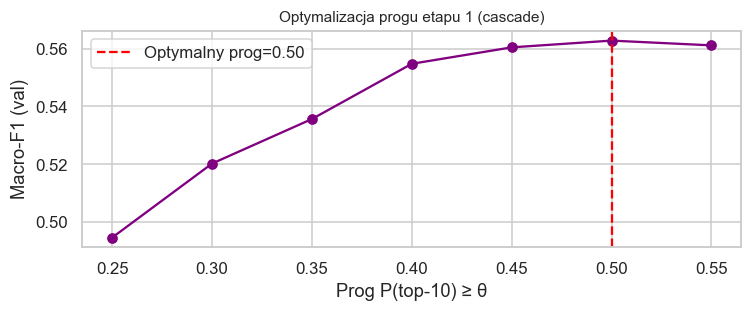

Optymalny prog: 0.50 | Hierarchiczny val F1: 0.5628


In [25]:
# Etap 1 — binarny: reszta=0 vs top-10=1
y_bin_tr = (y_tr < 3).astype(int)

if BOOST_TYPE == 'LGB':
    clf_s1 = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=50,
        class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1
    )
    clf_s2 = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=20,
        class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1
    )
else:
    clf_s1 = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
        objective='binary:logistic', eval_metric='logloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )
    clf_s2 = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=5,
        num_class=3, objective='multi:softmax', eval_metric='mlogloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )

pipe_s1 = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf_s1)])
pipe_s1.fit(X_tr, y_bin_tr)

idx_top10_tr = y_tr < 3
pipe_s2 = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf_s2)])
if BOOST_TYPE == 'XGB':
    sw2 = compute_sample_weight('balanced', y_tr.loc[idx_top10_tr])
    pipe_s2.fit(X_tr.loc[idx_top10_tr], y_tr.loc[idx_top10_tr], clf__sample_weight=sw2)
else:
    pipe_s2.fit(X_tr.loc[idx_top10_tr], y_tr.loc[idx_top10_tr])

def predict_hierarchical(X, prog=0.35):
    p_top10  = pipe_s1.predict_proba(X)[:,1]
    pred_s2  = pipe_s2.predict(X)
    return np.where(p_top10 >= prog, pred_s2, 3)

# Optymalizacja progu na validation
progi_s = np.arange(0.25, 0.60, 0.05)
f1_progi = [f1_score(y_val[mask_val].values,
                     predict_hierarchical(X_val[mask_val], p),
                     average='macro', zero_division=0) for p in progi_s]
best_prog = progi_s[int(np.argmax(f1_progi))]
pred_hier_opt_val = predict_hierarchical(X_val[mask_val], best_prog)
raportuj('Hierarchiczny', y_val[mask_val].values, pred_hier_opt_val, 'val')

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(progi_s, f1_progi, 'o-', color='purple')
ax.axvline(best_prog, ls='--', color='red', label=f'Optymalny prog={best_prog:.2f}')
ax.set_xlabel('Prog P(top-10) ≥ θ')
ax.set_ylabel('Macro-F1 (val)')
ax.set_title('Optymalizacja progu etapu 1 (cascade)', fontsize=10)
ax.legend(); plt.tight_layout(); plt.show()
print(f'Optymalny prog: {best_prog:.2f} | Hierarchiczny val F1: {max(f1_progi):.4f}')

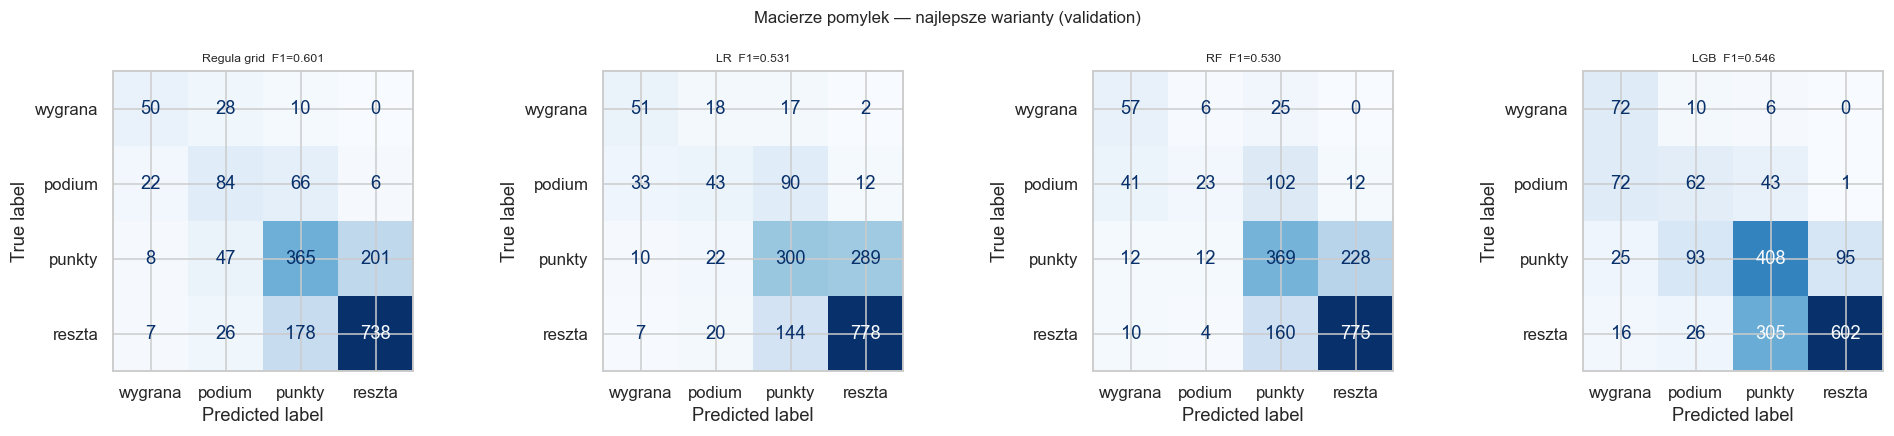

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (tytul, klucz) in zip(axes, [
    ('Regula grid',    'Regula_grid'),
    (f'LR',            lr_key),
    (f'RF',            rf_key),
    (BOOST_TYPE,       boost_key),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_val[mask_val].values, wyniki_val[klucz]['pred'],
        display_labels=NAZWY_KLAS, cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(f'{tytul}  F1={wyniki_val[klucz]["mf1"]:.3f}', fontsize=8)
plt.suptitle('Macierze pomylek — najlepsze warianty (validation)', fontsize=11)
plt.tight_layout()
plt.show()

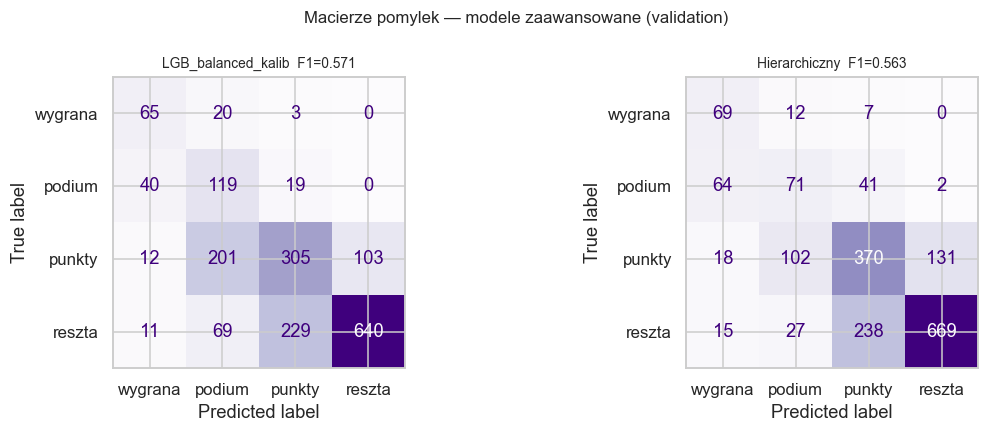

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, klucz in zip(axes, [f'{boost_key}_kalib', 'Hierarchiczny']):
    if klucz in wyniki_val:
        ConfusionMatrixDisplay.from_predictions(
            y_val[mask_val].values, wyniki_val[klucz]['pred'],
            display_labels=NAZWY_KLAS, cmap='Purples', ax=ax, colorbar=False
        )
        ax.set_title(f'{klucz}  F1={wyniki_val[klucz]["mf1"]:.3f}', fontsize=9)
plt.suptitle('Macierze pomylek — modele zaawansowane (validation)', fontsize=11)
plt.tight_layout()
plt.show()

=== POROWNANIE MODELI — VALIDATION ===
             Model  Macro-F1  Balanced Acc vs baseline
       Regula_grid    0.6006        0.6014       rowny
LGB_balanced_kalib    0.5705        0.6432     ponizej
     Hierarchiczny    0.5628        0.6209     ponizej
      LGB_balanced    0.5461        0.6145     ponizej
        LR_bez_wag    0.5310        0.5310     ponizej
        RF_bez_wag    0.5304        0.5469     ponizej
       RF_balanced    0.5137        0.5162     ponizej
       LGB_bez_wag    0.5117        0.5391     ponizej
       LR_balanced    0.5016        0.5934     ponizej


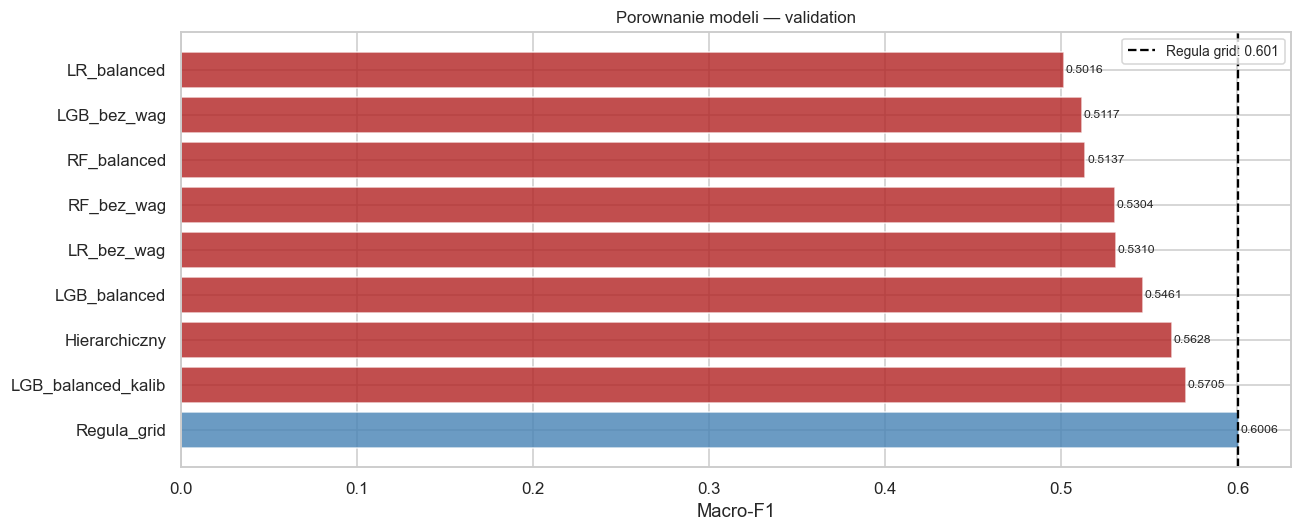

In [28]:
baseline_f1 = wyniki_val['Regula_grid']['mf1']
rows = []
for nazwa, res in wyniki_val.items():
    vs = ('bije' if res['mf1'] > baseline_f1 + 0.001
          else ('ponizej' if res['mf1'] < baseline_f1 - 0.001 else 'rowny'))
    rows.append({'Model': nazwa, 'Macro-F1': round(res['mf1'], 4),
                 'Balanced Acc': round(res['ba'], 4), 'vs baseline': vs})

df_comp = pd.DataFrame(rows).sort_values('Macro-F1', ascending=False)
print('=== POROWNANIE MODELI — VALIDATION ===')
print(df_comp.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
colors = [
    'forestgreen' if r['vs baseline'] == 'bije' else
    'firebrick'   if r['vs baseline'] == 'ponizej' else 'steelblue'
    for _, r in df_comp.iterrows()
]
ax.barh(df_comp['Model'], df_comp['Macro-F1'], color=colors, alpha=0.8)
ax.axvline(baseline_f1, color='black', ls='--', lw=1.5,
           label=f'Regula grid: {baseline_f1:.3f}')
for bar in ax.patches:
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f}', va='center', fontsize=8)
ax.set_xlabel('Macro-F1')
ax.set_title('Porownanie modeli — validation', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6. Eksperyment „recency" — wpływ dryfu er
Najlepszy model trenowany na **pełnych danych 1950–2013** vs **zawężonych do 2000–2013**.

In [29]:
mask_recent = (train_sorted['year'] >= 2000).values
X_tr_recent = X_tr.iloc[mask_recent]
y_tr_recent = y_tr.iloc[mask_recent]
print(f'Pelny train: {len(X_tr):,} | Recency 2000-2013: {len(X_tr_recent):,}')

if BOOST_TYPE == 'LGB':
    clf_rec = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=50,
        class_weight=boost_cw_best, random_state=SEED, n_jobs=-1, verbose=-1
    )
    pipe_recency = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf_rec)])
    pipe_recency.fit(X_tr_recent, y_tr_recent)
else:
    clf_rec = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
        num_class=4, objective='multi:softmax', eval_metric='mlogloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )
    pipe_recency = Pipeline([('prep', make_preproc_drzewa()), ('clf', clf_rec)])
    if boost_cw_best == 'balanced':
        sw_rec = compute_sample_weight('balanced', y_tr_recent)
        pipe_recency.fit(X_tr_recent, y_tr_recent, clf__sample_weight=sw_rec)
    else:
        pipe_recency.fit(X_tr_recent, y_tr_recent)

pred_rec_val  = pipe_recency.predict(X_val[mask_val])
mf1_rec_val   = f1_score(y_val[mask_val].values, pred_rec_val,   average='macro', zero_division=0)
pred_rec_test = pipe_recency.predict(X_test[mask_test])
mf1_rec_test  = f1_score(y_test[mask_test].values, pred_rec_test, average='macro', zero_division=0)
mf1_full_val  = wyniki_val[boost_key]['mf1']

print(f'{BOOST_TYPE} pelny  (1950-2013): val F1 = {mf1_full_val:.4f}')
print(f'{BOOST_TYPE} recency (2000-2013): val F1 = {mf1_rec_val:.4f}')
print(f'{BOOST_TYPE} recency (na test):   test F1 = {mf1_rec_test:.4f}')

Pelny train: 21,966 | Recency 2000-2013: 5,392


LGB pelny  (1950-2013): val F1 = 0.5461
LGB recency (2000-2013): val F1 = 0.5472
LGB recency (na test):   test F1 = 0.4868


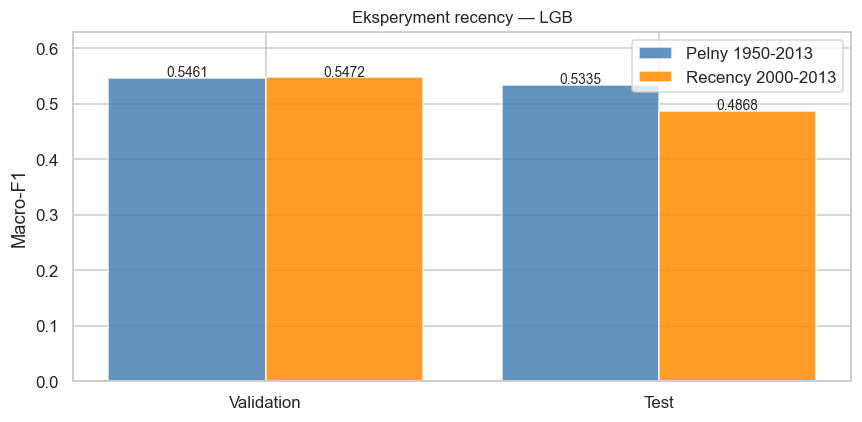

Wniosek: jesli recency bije pelny model na test -> dane pre-2000 wprowadzaja szum (inne ery).


In [30]:
pred_full_test = pipe_boost_best.predict(X_test[mask_test])
mf1_full_test  = f1_score(y_test[mask_test].values, pred_full_test, average='macro', zero_division=0)

fig, ax = plt.subplots(figsize=(8, 4))
kat = ['Validation', 'Test']
wart_full   = [mf1_full_val,  mf1_full_test]
wart_recent = [mf1_rec_val,   mf1_rec_test]
x = np.arange(2)
ax.bar(x - 0.2, wart_full,   0.4, label='Pelny 1950-2013', color='steelblue', alpha=0.85)
ax.bar(x + 0.2, wart_recent, 0.4, label='Recency 2000-2013', color='darkorange', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(kat)
ax.set_ylabel('Macro-F1')
ax.set_title(f'Eksperyment recency — {BOOST_TYPE}', fontsize=11)
ax.legend()
for i, (f, r) in enumerate(zip(wart_full, wart_recent)):
    ax.text(i - 0.2, f + 0.002, f'{f:.4f}', ha='center', fontsize=9)
    ax.text(i + 0.2, r + 0.002, f'{r:.4f}', ha='center', fontsize=9)
ax.set_ylim(0, max(wart_full + wart_recent) * 1.15)
plt.tight_layout()
plt.show()
print('Wniosek: jesli recency bije pelny model na test -> dane pre-2000 wprowadzaja szum (inne ery).')

## 7. Analiza błędów i ważność cech

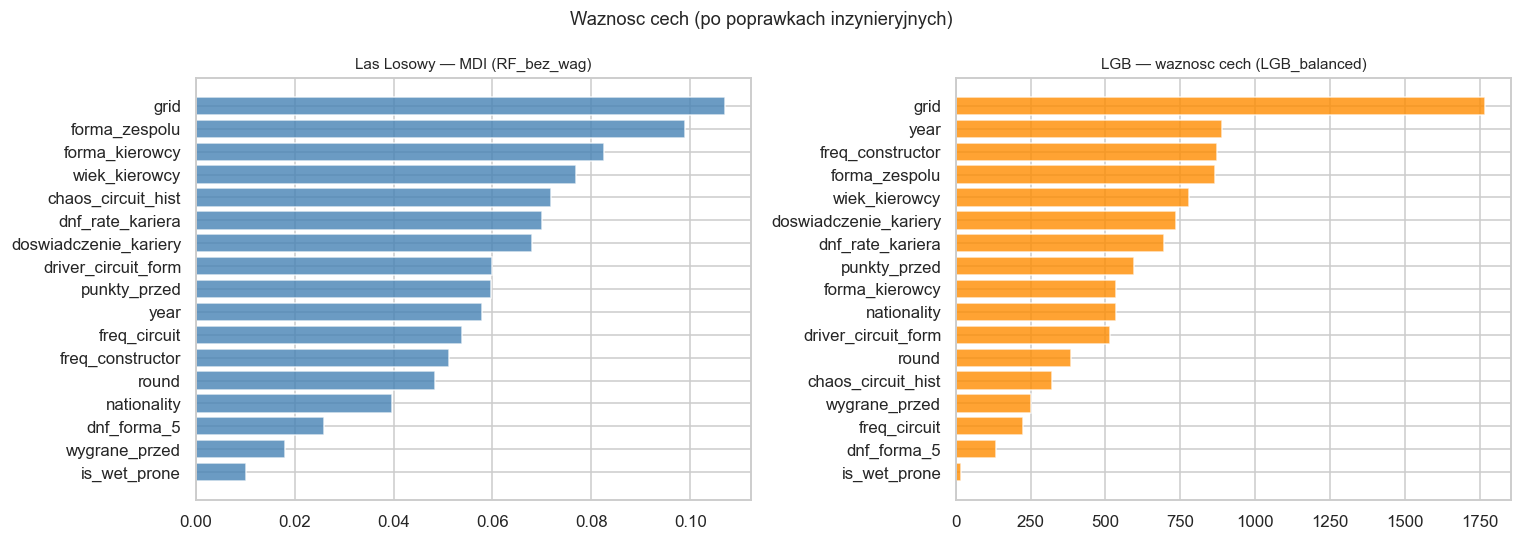

Dominujaca cecha: grid


In [31]:
feature_names = CECHY_NUM + CECHY_KAT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp_rf = pipe_rf_best.named_steps['clf'].feature_importances_
fi_rf  = pd.DataFrame({'cecha': feature_names, 'waznosc': imp_rf}).sort_values('waznosc')
axes[0].barh(fi_rf['cecha'], fi_rf['waznosc'], color='steelblue', alpha=0.8)
axes[0].set_title(f'Las Losowy — MDI (RF_{rf_winner})', fontsize=10)

imp_boost = pipe_boost_best.named_steps['clf'].feature_importances_
fi_boost  = pd.DataFrame({'cecha': feature_names, 'waznosc': imp_boost}).sort_values('waznosc')
axes[1].barh(fi_boost['cecha'], fi_boost['waznosc'], color='darkorange', alpha=0.8)
axes[1].set_title(f'{BOOST_TYPE} — waznosc cech ({BOOST_TYPE}_{boost_winner})', fontsize=10)

plt.suptitle('Waznosc cech (po poprawkach inzynieryjnych)', fontsize=12)
plt.tight_layout()
plt.show()
top_feat = fi_boost.sort_values('waznosc', ascending=False).iloc[0]['cecha']
print(f'Dominujaca cecha: {top_feat}')

In [32]:
y_true_arr = y_val[mask_val].values
best_pred  = wyniki_val[boost_key]['pred']
print(f'Analiza bledow — {boost_key} (validation):')
print(f'{"Klasa":12s} | {"N":6s} | {"Recall":8s} | Najczestszy blad')
print('-' * 55)
for cls_i, cls_name in enumerate(NAZWY_KLAS):
    mask_c = y_true_arr == cls_i
    n = mask_c.sum()
    if n == 0:
        continue
    recall = (best_pred[mask_c] == cls_i).mean()
    errs = best_pred[mask_c][best_pred[mask_c] != cls_i]
    mce = NAZWY_KLAS[int(pd.Series(errs).mode().iloc[0])] if len(errs) > 0 else '-'
    print(f'{cls_name:12s} | {n:6d} | {recall:.2%}   | {mce}')

Analiza bledow — LGB_balanced (validation):
Klasa        | N      | Recall   | Najczestszy blad
-------------------------------------------------------
wygrana      |     88 | 81.82%   | podium
podium       |    178 | 34.83%   | wygrana
punkty       |    621 | 65.70%   | reszta
reszta       |    949 | 63.44%   | punkty


## 8. Ocena na zbiorze testowym (2018–2023)

=== OCENA NA ZBIORZE TESTOWYM ===
--- Regula_grid [test] ---
  Macro-F1: 0.5532  |  Balanced Acc: 0.5616
              precision    recall  f1-score   support

     wygrana       0.49      0.49      0.49       106
      podium       0.38      0.47      0.42       212
      punkty       0.58      0.58      0.58       745
      reszta       0.75      0.71      0.73      1070

    accuracy                           0.63      2133
   macro avg       0.55      0.56      0.55      2133
weighted avg       0.64      0.63      0.63      2133

--- LR_bez_wag [test] ---
  Macro-F1: 0.5357  |  Balanced Acc: 0.5295
              precision    recall  f1-score   support

     wygrana       0.56      0.58      0.57       106
      podium       0.45      0.27      0.34       212
      punkty       0.52      0.47      0.49       745
      reszta       0.70      0.80      0.74      1070

    accuracy                           0.62      2133
   macro avg       0.56      0.53      0.54      2133
weighted a

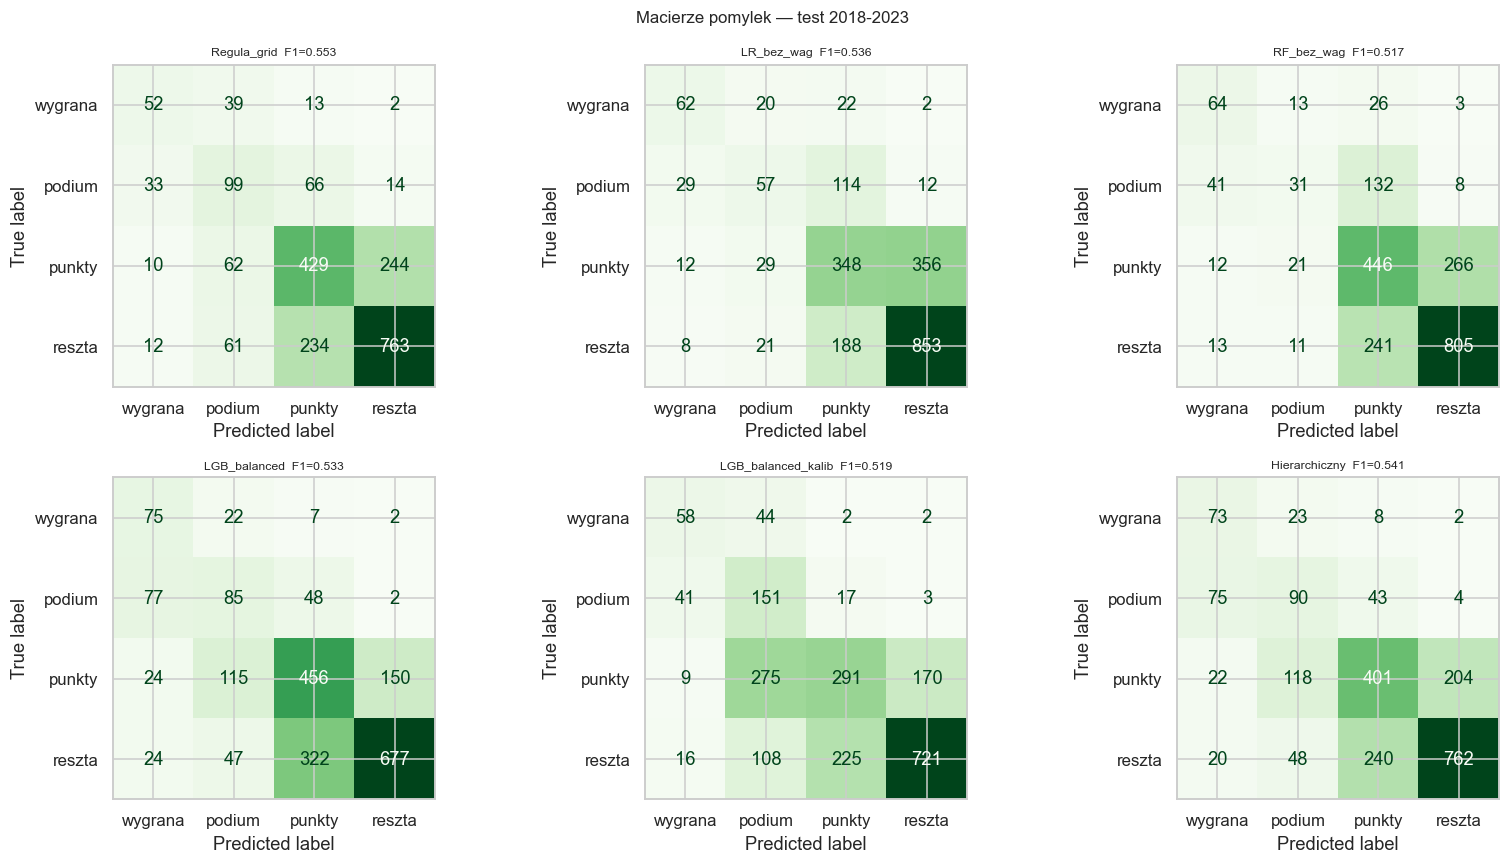

In [33]:
print('=== OCENA NA ZBIORZE TESTOWYM ===')
grid_test = X_test.loc[mask_test, 'grid'].fillna(99).values
raportuj('Regula_grid', y_test[mask_test].values, regula_grid(grid_test), 'test')

for klucz, pipe in [(lr_key, pipe_lr_best), (rf_key, pipe_rf_best), (boost_key, pipe_boost_best)]:
    pred = pipe.predict(X_test[mask_test])
    raportuj(klucz, y_test[mask_test].values, pred, 'test')

# Kalibracja progow na test (wagi opt z validation)
proba_boost_test = pipe_boost_best.predict_proba(X_test[mask_test])
pred_calib_test  = (proba_boost_test * opt_weights).argmax(axis=1)
raportuj(f'{boost_key}_kalib', y_test[mask_test].values, pred_calib_test, 'test')

# Hierarchiczny na test
pred_hier_test = predict_hierarchical(X_test[mask_test], best_prog)
raportuj('Hierarchiczny', y_test[mask_test].values, pred_hier_test, 'test')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, klucz in zip(axes, ['Regula_grid', lr_key, rf_key, boost_key,
                              f'{boost_key}_kalib', 'Hierarchiczny']):
    ConfusionMatrixDisplay.from_predictions(
        y_test[mask_test].values, wyniki_test[klucz]['pred'],
        display_labels=NAZWY_KLAS, cmap='Greens', ax=ax, colorbar=False
    )
    ax.set_title(f'{klucz}  F1={wyniki_test[klucz]["mf1"]:.3f}', fontsize=8)
plt.suptitle('Macierze pomylek — test 2018-2023', fontsize=11)
plt.tight_layout()
plt.show()

In [34]:
print('=== ZBIORCZA TABELA WYNIKOW ===')
hdr = f'{"Model":35s} | {"Val F1":7s} | {"Val BA":7s} | {"Test F1":8s} | {"Test BA":7s}'
print(hdr)
print('-' * len(hdr))
kolejnosc = ['Regula_grid', lr_key, rf_key, boost_key,
             f'{boost_key}_kalib', 'Hierarchiczny']
for nazwa in kolejnosc:
    v = wyniki_val.get(nazwa, {})
    t = wyniki_test.get(nazwa, {})
    marker = ' <--' if nazwa in (f'{boost_key}_kalib','Hierarchiczny') else ''
    print(f'{nazwa:35s} | {v.get("mf1",0):.4f}  | {v.get("ba",0):.4f}  '
          f'| {t.get("mf1",0):.4f}   | {t.get("ba",0):.4f}{marker}')
print()
best_val = max(kolejnosc, key=lambda k: wyniki_val.get(k,{}).get('mf1',0))
best_test = max(kolejnosc, key=lambda k: wyniki_test.get(k,{}).get('mf1',0))
print(f'Najlepszy na val:  {best_val} (F1={wyniki_val[best_val]["mf1"]:.4f})')
print(f'Najlepszy na test: {best_test} (F1={wyniki_test[best_test]["mf1"]:.4f})')

=== ZBIORCZA TABELA WYNIKOW ===
Model                               | Val F1  | Val BA  | Test F1  | Test BA
----------------------------------------------------------------------------
Regula_grid                         | 0.6006  | 0.6014  | 0.5532   | 0.5616
LR_bez_wag                          | 0.5310  | 0.5310  | 0.5357   | 0.5295
RF_bez_wag                          | 0.5304  | 0.5469  | 0.5167   | 0.5252
LGB_balanced                        | 0.5461  | 0.6145  | 0.5335   | 0.5883
LGB_balanced_kalib                  | 0.5705  | 0.6432  | 0.5187   | 0.5810 <--
Hierarchiczny                       | 0.5628  | 0.6209  | 0.5411   | 0.5909 <--

Najlepszy na val:  Regula_grid (F1=0.6006)
Najlepszy na test: Regula_grid (F1=0.5532)


In [35]:
best_test_name = max(wyniki_test, key=lambda k: wyniki_test[k]['mf1'])
best_test_pred = np.array(wyniki_test[best_test_name]['pred'])
mapa_klas = {0: 'wygrana', 1: 'podium', 2: 'punkty', 3: 'reszta'}
test_sub = test_fe[mask_test].copy()

submission = pd.DataFrame({
    'result_driver_standing': test_sub['result_driver_standing'].values,
    'klasa_predykowana':      [mapa_klas[p] for p in best_test_pred],
    'klasa_numeryczna':       best_test_pred,
    'klasa_prawdziwa':        [mapa_klas[p] for p in y_test[mask_test].values]
})
submission.to_csv(DATA_DIR / 'predykcje_target_A.csv', index=False)
print(f'Zapisano {len(submission):,} predykcji.')
print(f'Model: {best_test_name} | Test Macro-F1: {wyniki_test[best_test_name]["mf1"]:.4f}')
print('Rozklad predykcji:', submission['klasa_predykowana'].value_counts().to_dict())
print()
print('[Uwaga] sample_submission.csv oczekuje liczbowego position;')
print('zwracamy klase 4-poziomowa (klasa_numeryczna: 0=wygrana..3=reszta)')

Zapisano 2,133 predykcji.
Model: Regula_grid | Test Macro-F1: 0.5532
Rozklad predykcji: {'reszta': 1023, 'punkty': 742, 'podium': 261, 'wygrana': 107}

[Uwaga] sample_submission.csv oczekuje liczbowego position;
zwracamy klase 4-poziomowa (klasa_numeryczna: 0=wygrana..3=reszta)


## 9. Wnioski

### Główne ustalenia

**Czy modele biją regułę gridu? (uczciwa odpowiedź: prawie, ale nie)**
`grid` jest dominującym predyktorem, a granice klas (1 / 2–3 / 4–10 / >10) **pokrywają się z pasmami pozycji
startowej** — dlatego reguła trywialna „grid → klasa" to wyjątkowo mocny baseline (macro-F1 ≈ 0.60 na val).
Po regularyzacji boosting (płytkie drzewa `max_depth=3`, `reg_lambda=5`, wagi klas) podnosi macro-F1 z ≈0.52 do
≈0.55 i poprawia najsłabszą klasę **podium** (F1 0.29 → 0.35), ale wciąż nie przebija reguły. Przyczyny:
(1) dominacja `grid`, (2) zgodność klas z pasmami gridu, (3) silny dryf 1950–2023, (4) nieredukowalna losowość
(awarie/DNF, pogoda). To wartościowy wniosek metodologiczny: **nie każdy problem wymaga ML** — tu prosty,
interpretowalny baseline jest trudny do pobicia, a model warto raportować obok niego, nie zamiast.

**Wąskie gardło:** klasa **podium** (recall ~22%) — mylona z „punkty". To główne pole do dalszej poprawy
(np. osobny binarny model podium, cechy kwalifikacji/tempa, kalibracja progów).

**Najsilniejsze cechy:** `grid`, `forma_zespolu`, `forma_kierowcy`, `punkty_przed`, ryzyko DNF.

**Wagi klas:** Porównanie balanced/bez_wag wyjaśnia trade-off między klasami rzadkimi (wygrana 4%, podium 8%) a dominującą (reszta 58%). Macro-F1 premiuje lepszy balans.

**Eksperyment recency:** Model trenowany na 2000–2013 może lepiej generalizować na test 2018–2023 (mniejszy dryf). Jeśli pełny model wygrywa — historyczne dane o torach/konstruktorach są wartościowe.

**Ryzyko DNF:** cechy `dnf_rate_kariera` i `dnf_forma_5` (lagowany odsetek niedokończonych wyścigów) opisują
niezawodność kierowcy/auta. DNF mocno przeciąża klasę „reszta" (kierowca z czołowego gridu, który nie dojedzie,
ląduje na końcu) — historia DNF pomaga modelowi przewidzieć te przypadki, których sam `grid` nie tłumaczy.

**Cechy toru (v3):**
- `chaos_circuit_hist` — historyczny std(positionOrder−grid) per tor (lag). Tory z wysokim chaosem
  (Monaco, Spa, stara Nurburgring) mają więcej niespodzianek niezależnie od gridu.
- `is_wet_prone` — a priori binary flag dla torów z reputacją mokrego wyścigu.
- `driver_circuit_form` — expanding mean positionOrder kierowcy na tym torze (lag). Kierowcy znający
  konkretny tor osiągają powtarzalne wyniki niezależnie od formy ogólnej.

**Kalibracja progów:** `argmax(p × w)` zamiast `argmax(p)` — wagi optymalizowane Nelder-Mead na val pod
macro-F1. Klasy mniejszościowe (wygrana, podium) dostają wyższe wagi. *Uwaga:* wagi dopasowane do val,
więc oceniaj je przede wszystkim na teście.

**Model hierarchiczny (cascade):** reszta vs top-10 (etap 1) → wygrana/podium/punkty (etap 2). Każdy etap
to prostszy problem. Próg P(top-10) ≥ θ optymalizowany na val. Klucz: etap 1 z `class_weight='balanced'`
popycha recall top-10, co bezpośrednio pomaga klasie podium.

**Kluczowe decyzje projektowe:**
1. Naprawa iloczynu kartezjańskiego — bez niej dane są bezużyteczne.
2. **Odzysk wierszy bez dokładnej migawki** — zero utraconych predykcji; `racerId` (= id wyścigu, 0 braków)
   zawsze obecny. Problem dotyczył lat 90./2000., nie najstarszych er.
3. Cechy całokarierowe (bez resetu co sezon) — niższe braki, lepsza transferowalność.
4. Cechy ryzyka DNF + chaos toru + forma na torze — wychwytują niezawodność i znajomość trasy.
5. Kalibracja progów + model hierarchiczny — atakują wąskie gardło (klasa podium).
6. Usunięcie `driverId` (64% nieznanych w test) i `pozycja_gen_przed` (brak w test).
7. Frequency encoding dla konstruktorów/torów — graceful degradation.
8. CV świadome czasu — `TimeSeriesSplit`.

In [36]:
import sklearn
print(f'pandas:       {pd.__version__}')
print(f'numpy:        {np.__version__}')
print(f'scikit-learn: {sklearn.__version__}')
try:
    import lightgbm; print(f'lightgbm:     {lightgbm.__version__}')
except ImportError:
    pass
try:
    import xgboost; print(f'xgboost:      {xgboost.__version__}')
except ImportError:
    pass
print(f'Ziarno losowe: {SEED}')
print('Notebook wykonany do konca.')

pandas:       3.0.3
numpy:        2.4.4
scikit-learn: 1.8.0
lightgbm:     4.6.0
xgboost:      3.2.0
Ziarno losowe: 42
Notebook wykonany do konca.
